No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


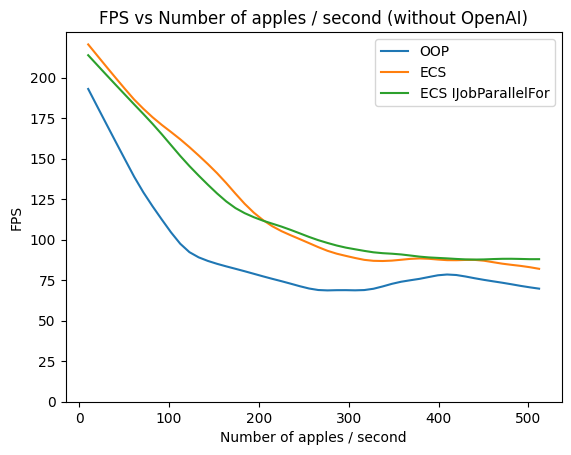

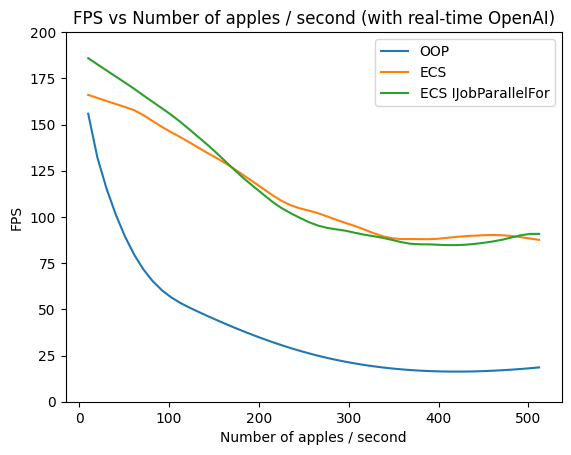

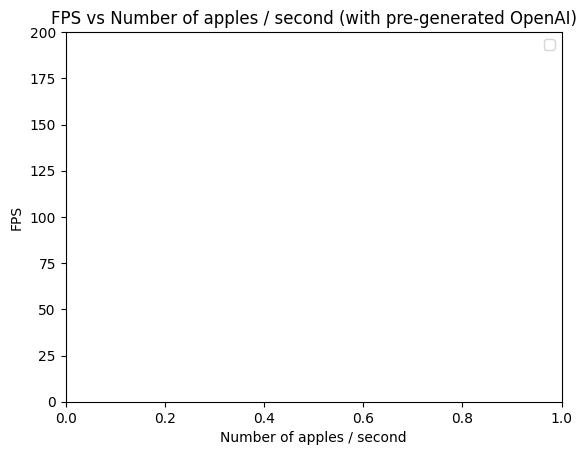

In [24]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib import pyplot as plt
from scipy.interpolate import interp1d


TYPES = ['normal', 'openai', 'openai_pregen']
STYLES = ['oop', 'dots', 'dots_parallel']

LABELS = {
    'oop': 'OOP',
    'dots': 'ECS',
    'dots_parallel': 'ECS IJobParallelFor'
}

TITLES = {
    'normal': 'without OpenAI',
    'openai': 'with real-time OpenAI',
    'openai_pregen': 'with pre-generated OpenAI'
}

for t in TYPES:
    plt.figure()
    for s in STYLES:
        try:
            with open(f'{t}_{s}.csv'):
                pass
        except FileNotFoundError:
            continue

        df = pd.read_csv(f'{t}_{s}.csv')
        if df.empty:
            continue
        df = df.groupby('num_apples').mean()

        smooth = sm.nonparametric.lowess(df['fps'], df.index, frac=0.2)
        x = smooth[:, 0]
        y = smooth[:, 1]

        curve = interp1d(x, y, kind='cubic')
        x = np.linspace(10, 512, num=50, endpoint=True)
        y = curve(x)

        plt.plot(x, y, label=LABELS[s])

    plt.xlabel('Number of apples / second')
    plt.ylabel('FPS')
    plt.legend()

    plt.yticks(range(0, 225, 25))

    title = f'FPS vs Number of apples / second ({TITLES[t]})'
    plt.title(title)
